# 05 · Fee income
Questions 17–22: where fee income comes from, what failures cost in fees, and whether customers were charged correctly.

In [1]:
import sys, pathlib, json
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data_loader import get_engine, query, PROJECT_ROOT
from src import analysis as an
an.set_style()
pd.set_option("display.float_format", "{:,.2f}".format); pd.set_option("display.max_columns", 30)
engine = get_engine()
o = an.sql_output

,month,total_kes_k,mobile_app_kes_k,ussd_kes_k,agent_kes_k,atm_kes_k,internet_banking_kes_k,fee_per_successful_txn
0,2025-05-01,"2,101.00",613.00,195.00,438.00,294.00,561.00,26.31
17,2026-10-01,"3,752.00","1,219.00",224.00,744.00,535.00,"1,029.00",26.36


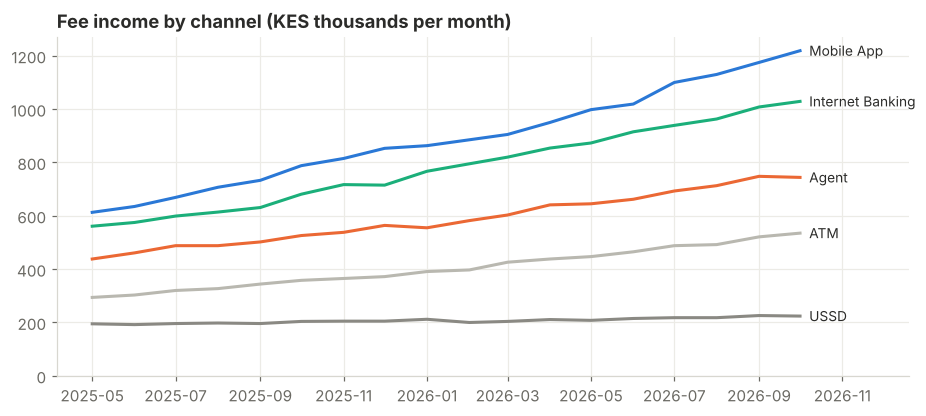

In [2]:
f = o('q17_fee_income_by_channel_month'); f['month'] = pd.to_datetime(f.month)
fig, ax = plt.subplots(figsize=(10, 4))
for col, name, color in [('mobile_app_kes_k','Mobile App',an.PRIMARY), ('internet_banking_kes_k','Internet Banking',an.SECOND),
                          ('agent_kes_k','Agent',an.HIGHLIGHT), ('atm_kes_k','ATM',an.CONTEXT), ('ussd_kes_k','USSD','#8a8983')]:
    ax.plot(f.month, f[col], color=color); ax.annotate(name, (f.month.iloc[-1], f[col].iloc[-1]), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9)
ax.set_title("Fee income by channel (KES thousands per month)"); ax.set_ylim(0); ax.set_xlim(right=f.month.iloc[-1] + pd.Timedelta(days=80))
an.save(fig, "fee_income_by_channel"); f.iloc[[0, -1]]

In [3]:
o('q18_fee_income_by_segment')

,segment,customers,fee_income_kes_m,share_of_fees_pct,fee_per_customer_kes,share_of_value_pct
0,SME,3364,21.45,41.50,"6,375.00",63.60
1,Salaried,5634,10.79,20.90,"1,915.00",11.50
2,Mass Retail,10922,8.38,16.20,768.00,4.90
3,Premier,1738,6.64,12.80,"3,819.00",17.60
4,Youth,5951,4.46,8.60,750.00,2.30


SME and Premier customers are 18% of the base and pay more than half of all fees (54%), mostly through interbank transfers.

Unrecovered operational failures: 16,822; fee income lost: KES 632,764; value not completed: KES 251M


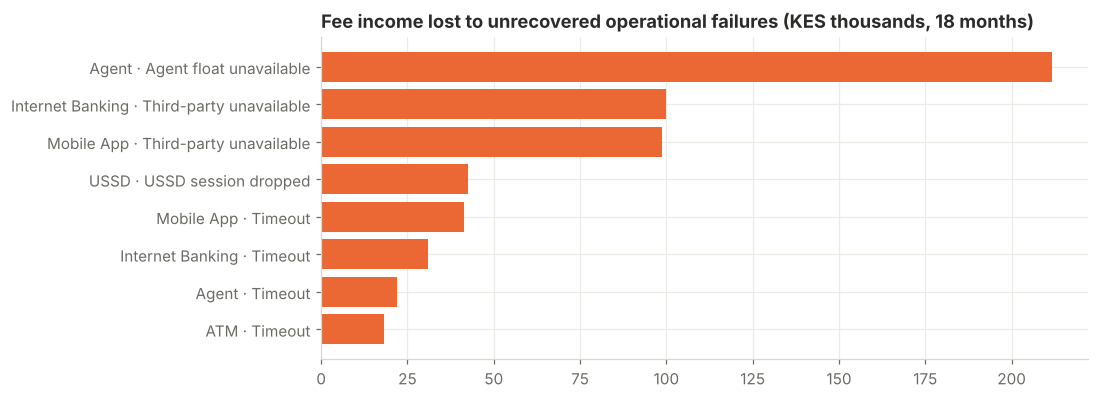

In [4]:
fl = o('q19_fees_lost_to_failures')
detail = fl.dropna(subset=['channel', 'failure_reason']).sort_values('fees_lost_kes', ascending=True).tail(8)
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(detail.channel + ' · ' + detail.failure_reason, detail.fees_lost_kes / 1e3, color=an.HIGHLIGHT)
ax.set_title("Fee income lost to unrecovered operational failures (KES thousands, 18 months)")
an.save(fig, "fees_lost_to_failures")
total = fl[fl.channel.isna()].iloc[0]
print(f"Unrecovered operational failures: {int(total.not_recovered):,}; fee income lost: KES {total.fees_lost_kes:,.0f}; value not completed: KES {total.value_not_completed_kes_m:,.0f}M")

Unrecovered operational failures cost about **KES 0.6M of fee income** over 18 months (about 1.2% of fee income). **Agent float shortages are the single largest item**, because a failed agent withdrawal is a high-fee transaction. The value that never moved (about KES 250M) matters more to customers than the fee does to the bank.

In [5]:
o('q20_fee_billing_exceptions')

,issue,channel,transaction_type,first_seen,last_seen,transactions,customers_affected,overcharge_kes
0,Fee charged on a failed transaction,Mobile App,Interbank Transfer,2026-03-02,2026-04-12,371,360,"38,910.00"
1,Charged above tariff,Mobile App,Send to Mobile Wallet,2026-02-01,2026-02-14,2634,2302,"26,340.00"
2,Fee charged on a failed transaction,Mobile App,Send to Mobile Wallet,2026-03-02,2026-04-12,546,515,"17,970.00"
3,Fee charged on a failed transaction,USSD,Send to Mobile Wallet,2026-03-02,2026-04-12,500,474,"13,224.00"


In [6]:
b = o('q20_fee_billing_exceptions')
print(f"Transactions charged against the tariff: {b.transactions.sum():,}; overcharge to refund: KES {b.overcharge_kes.sum():,.0f}")

Transactions charged against the tariff: 4,051; overcharge to refund: KES 96,444


**Two fee-engine defects**, found by recomputing every fee from the tariff:
1. **1–14 Feb 2026:** the KES 10 fee was still charged on app wallet transfers of KES 101–1,000 after they became free on 1 February.
2. **2 Mar – 12 Apr 2026:** fees were charged on *failed* wallet and interbank transfers.

The total is small (about KES 96k), but it affects thousands of customers and is a conduct issue: overcharges should be refunded and the fee engine needs a reconciliation control. **Nothing in the cleaning step "fixed" these fees.** They are kept as charged, because the difference is the finding.

In [7]:
w = o('q21_wallet_fee_waiver')
w

,period,channel,transfers,share_of_small_transfers_pct,fees_kes,tariff_fees_kes
0,a) Before waiver (Aug 2025 - Jan 2026),Mobile App,24702,60.40,"239,020.00","239,020.00"
1,a) Before waiver (Aug 2025 - Jan 2026),USSD,16214,39.60,"188,676.00","188,676.00"
2,b) After waiver (Feb - Jul 2026),Mobile App,36517,75.10,"26,340.00",0.00
3,b) After waiver (Feb - Jul 2026),USSD,12105,24.90,"140,868.00","140,868.00"


Fee foregone by the waiver, Feb - Oct 2026: KES 562,320 (about KES 62k a month)


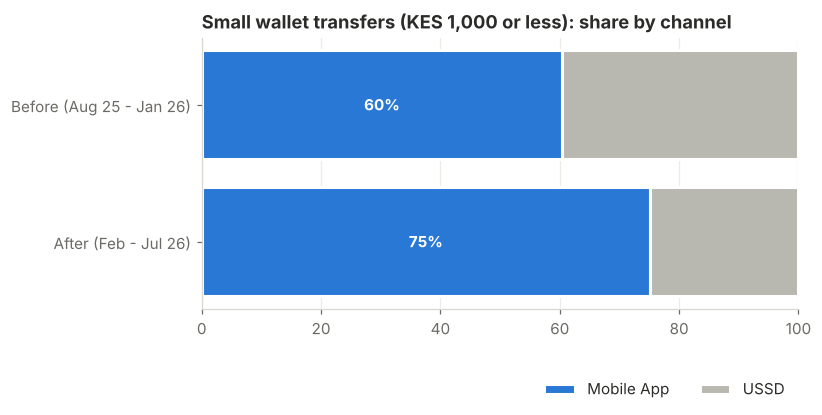

In [8]:
p = w.pivot(index='period', columns='channel', values='share_of_small_transfers_pct')
fig, ax = plt.subplots(figsize=(7, 3.2))
y = np.arange(len(p))[::-1]; ax.barh(y, p['Mobile App'], color=an.PRIMARY, label='Mobile App', edgecolor='white', linewidth=2)
ax.barh(y, p['USSD'], left=p['Mobile App'], color=an.CONTEXT, label='USSD', edgecolor='white', linewidth=2)
for yi, v in zip(y, p['Mobile App']): ax.text(v/2, yi, f"{v:.0f}%", color='white', va='center', ha='center', fontweight='bold')
ax.set_yticks(y, ['Before (Aug 25 - Jan 26)', 'After (Feb - Jul 26)']); ax.set_xlim(0, 100)
ax.set_title("Small wallet transfers (KES 1,000 or less): share by channel"); ax.legend(loc='lower right', ncol=2, bbox_to_anchor=(1, -0.38))
an.save(fig, "wallet_waiver_effect")
fz = o('q22_waiver_fee_foregone'); print(f"Fee foregone by the waiver, Feb - Oct 2026: KES {fz.fee_foregone_kes.sum():,.0f} (about KES {fz.fee_foregone_kes.mean()/1e3:,.0f}k a month)")

The waiver did what it was meant to do: the app's share of small wallet transfers rose from about 60% to 75%, moving traffic off USSD, the least reliable channel. It costs about KES 60–70k of fee income a month, roughly 2% of fee income. Customers who switched also stopped paying the USSD fee (KES 12), so the true cost is a little higher; that is a trade-off management chose.